# 04.1 Árbol de decisión (experimento 1)

- Entrada: `data/processed/dev_features.csv` (salida del notebook 03)
- Salida: resultados de validación cruzada de este modelo, para compararlos con los demás

Instrucciones:

- Validación: `GroupKFold(n_splits=5, shuffle=True, random_state=SEED)` agrupando por `animal_id_intake`. Es la misma en todos los notebooks.
- Hiperparámetros: salen de la búsqueda con Optuna del mismo modelo (carpeta `04-hyperparameter-optimization-experiment-1`), con `load_best(...)` y los nombres `tree_clf` y `tree_reg`. Si las variables o los datos cambian, hay que repetir esa búsqueda.
- Preprocesamiento: `build_preprocessor(columns=...)` dentro de un `Pipeline`, para que se ajuste en cada fold.
- Métricas: clasificación con macro-F1 y reporte por clase. Regresión con MAE en días (`np.expm1`) y R² en log.
- Resultados por fold: mostrar también el resultado de cada fold, como en `04.1-svm.ipynb` (sección 4).
- No usar `test`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline

from config import SEED
from features import CAT_LOW, CAT_HIGH, BINARY, NUMERIC, FEATURES, build_preprocessor
from tuning import load_best

data = pd.read_csv("../../data/processed/dev_features.csv")
groups = data["animal_id_intake"]
cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)

c:\Users\andre\mucsi-deusto-code\machine-learning\mucsi-ml-animal-shelter-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Inputs

- `AVAILABLE`: las 22 variables de `dev_features.csv`.
- `FEATURES_EXP1_CLF` y `FEATURES_EXP1_REG`: variables del experimento 1 para este modelo, en clasificación y en regresión. Los árboles eligen solos las variables útiles.

In [2]:
AVAILABLE = FEATURES
FEATURES_EXP1_CLF = AVAILABLE
FEATURES_EXP1_REG = AVAILABLE

print("El experimento 1 usa estas variables:")
print("Clasificación:", FEATURES_EXP1_CLF)
print("Regresión:", FEATURES_EXP1_REG)

# Clasificación: todas las filas
y_clf = data["y_outcome"]

# Regresión: solo adoptados
adopted = data["y_outcome"] == "Adoption"
y_reg = data.loc[adopted, "y_log_days"]
groups_reg = groups[adopted]

El experimento 1 usa estas variables:
Clasificación: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']
Regresión: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']


In [3]:
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_predict
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

## Hiperparámetros

Salen de la búsqueda con Optuna del experimento 1. Si las variables o los datos cambiaron desde esa búsqueda, `load_best` se detiene y avisa que hay que repetirla.

In [4]:
params_clf = load_best("tree_clf", FEATURES_EXP1_CLF)
params_reg = load_best("tree_reg", FEATURES_EXP1_REG)

Ajustes cargados de tree_clf.json: {'max_depth': 12, 'min_samples_leaf': 1, 'class_weight': None}
(en la búsqueda: macro-F1 = 0.5461)
Ajustes cargados de tree_reg.json: {'max_depth': 29, 'min_samples_leaf': 79}
(en la búsqueda: R² (en log) = 0.3467)


## 1. Clasificación

Se evalúa con todos los datos. Cada fila se predice con un modelo que no la vio.

macro-F1: 0.547  (siempre la clase más frecuente: 0.119)

                 precision    recall  f1-score   support

       Adoption       0.61      0.78      0.69     27073
     Euthanasia       0.75      0.62      0.68      4986
          Other       0.42      0.14      0.21       834
Return to Owner       0.63      0.61      0.62     11757
       Transfer       0.66      0.46      0.54     19031

       accuracy                           0.63     63681
      macro avg       0.61      0.52      0.55     63681
   weighted avg       0.64      0.63      0.62     63681



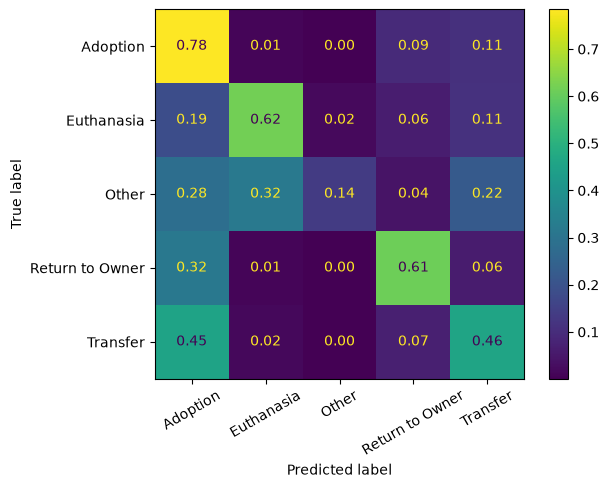

In [5]:
pipe_clf = Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP1_CLF)), ("model", DecisionTreeClassifier(random_state=SEED, **params_clf))])
X_clf = data[FEATURES_EXP1_CLF]

pred_clf = cross_val_predict(pipe_clf, X_clf, y_clf, groups=groups, cv=cv, n_jobs=5)
base_clf = cross_val_predict(DummyClassifier(strategy="most_frequent"), X_clf, y_clf, groups=groups, cv=cv)

print(f"macro-F1: {f1_score(y_clf, pred_clf, average='macro'):.3f}  (siempre la clase más frecuente: {f1_score(y_clf, base_clf, average='macro'):.3f})\n")
print(classification_report(y_clf, pred_clf))

ConfusionMatrixDisplay.from_predictions(y_clf, pred_clf, normalize="true", xticks_rotation=30, values_format=".2f")
plt.show()

## 2. Regresión

El error se reporta en días (`np.expm1`) y el R² en log.

In [6]:
pipe_reg = Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP1_REG)), ("model", DecisionTreeRegressor(random_state=SEED, **params_reg))])
X_reg = data.loc[adopted, FEATURES_EXP1_REG]

pred_log = cross_val_predict(pipe_reg, X_reg, y_reg, groups=groups_reg, cv=cv, n_jobs=5)
base_log = cross_val_predict(DummyRegressor(strategy="median"), X_reg, y_reg, groups=groups_reg, cv=cv)

days_real = np.expm1(y_reg)
pd.DataFrame({
    "R² (log)": [r2_score(y_reg, pred_log), r2_score(y_reg, base_log)],
    "MAE (días)": [mean_absolute_error(days_real, np.expm1(pred_log)), mean_absolute_error(days_real, np.expm1(base_log))],
}, index=["Árbol de decisión", "Siempre la mediana"]).round(3)

,R² (log),MAE (días)
Árbol de decisión,0.347,19.492
Siempre la mediana,-0.058,24.312


## 3. Resultados

In [7]:
pd.DataFrame({
    "Clasificación (macro-F1)": [round(f1_score(y_clf, pred_clf, average="macro"), 3)],
    "Regresión (R² log)": [round(r2_score(y_reg, pred_log), 3)],
    "Regresión (MAE días)": [round(mean_absolute_error(days_real, np.expm1(pred_log)), 3)],
}, index=["Árbol de decisión"])

,Clasificación (macro-F1),Regresión (R² log),Regresión (MAE días)
Árbol de decisión,0.547,0.347,19.492


## 4. Resultados por fold

Cada fold deja fuera un grupo distinto de animales para evaluar. Estos son los resultados de cada uno, con los mismos folds en todos los modelos, así que se pueden comparar fold por fold. No vuelve a entrenar nada: usa las predicciones de arriba.

In [8]:
rows_clf = []
for fold, (_, val) in enumerate(cv.split(X_clf, y_clf, groups), start=1):
    rows_clf.append({"fold": fold, "filas": len(val),
                     "macro-F1": f1_score(y_clf.iloc[val], pred_clf[val], average="macro"),
                     "exactitud": (pred_clf[val] == y_clf.iloc[val]).mean()})

rows_reg = []
for fold, (_, val) in enumerate(cv.split(X_reg, y_reg, groups_reg), start=1):
    rows_reg.append({"fold": fold, "filas": len(val),
                     "R² (log)": r2_score(y_reg.iloc[val], pred_log[val]),
                     "MAE (días)": mean_absolute_error(days_real.iloc[val], np.expm1(pred_log[val]))})

for title, rows in [("Clasificación", rows_clf), ("Regresión", rows_reg)]:
    table = pd.DataFrame(rows).set_index("fold")
    summary = table.drop(columns="filas").agg(["mean", "std"])
    print(f"=== {title}: resultado por fold ===")
    print(table.round(3).to_string())
    print(summary.round(3).to_string(), "\n")

=== Clasificación: resultado por fold ===
      filas  macro-F1  exactitud
fold                            
1     12729     0.538      0.632
2     12783     0.550      0.629
3     12697     0.549      0.631
4     12733     0.531      0.634
5     12739     0.563      0.641
      macro-F1  exactitud
mean     0.546      0.633
std      0.012      0.004 

=== Regresión: resultado por fold ===
      filas  R² (log)  MAE (días)
fold                             
1      5393     0.349      19.835
2      5453     0.333      19.494
3      5401     0.374      19.524
4      5405     0.329      19.548
5      5421     0.349      19.063
      R² (log)  MAE (días)
mean     0.347      19.493
std      0.018       0.276 

